# 03 — Experiments (self-contained / Colab-ready)

No `src` imports and no generated module: the core is defined directly in the
cells below, one component per block. Run the cells in order.

Contents: component-study table, median-filter grid, EPN `k`/`m` sensitivity,
and boundary-error analysis. It uses the 300-clip sample checkpoint by default
so it stays fast; point `CKPT`/`DATA_ROOT` at the full run for real numbers.


## 0. Setup

All imports are intentionally collected in the next cell; the component blocks
below do not import anything themselves.


In [1]:
import csv
import json
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, Iterable, List, Optional, Sequence, Tuple

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent

device = (
    torch.device("cuda") if torch.cuda.is_available()
    else torch.device("mps") if torch.backends.mps.is_available()
    else torch.device("cpu")
)
print("device:", device)

device: mps


## 1. Data Processing

### 1.1 Frontend configuration

`SEDConfig` records the log-mel frontend and the model widths. The processed
features must use the same `sample_rate`, `hop_length` and `n_mels`.

In [2]:
EPN_VARIANTS = ("per_class", "single")

@dataclass
class SEDConfig:

    # --- task ---
    num_classes: int = 0

    # --- log-mel frontend (must match the precomputed features) ---
    sample_rate: int = 16000
    n_fft: int = 1024
    win_length: int = 400  # 25 ms at 16 kHz
    hop_length: int = 320  # 20 ms -> 50 frames/s
    n_mels: int = 64
    f_min: float = 0.0
    f_max: float = 8000.0
    num_frames: int = 500  # 10 s clips

    # --- CRNN backbone ---
    cnn_channels: Tuple[int, ...] = (16, 32, 64, 128)
    rnn_hidden: int = 128
    rnn_layers: int = 2
    dropout: float = 0.3

    # --- RED / EPN ---
    use_red: bool = True
    use_epn: bool = True
    epn_variant: str = "per_class"
    epn_hidden: int = 32
    epn_layers: int = 2

    def __post_init__(self) -> None:
        if self.num_classes < 0:
            raise ValueError(f"num_classes must be >= 0, got {self.num_classes}")
        if self.sample_rate <= 0 or self.hop_length <= 0:
            raise ValueError("sample_rate and hop_length must be > 0")
        if self.num_frames <= 0:
            raise ValueError(f"num_frames must be > 0, got {self.num_frames}")
        if self.n_mels <= 0:
            raise ValueError(f"n_mels must be > 0, got {self.n_mels}")
        if not self.cnn_channels or any(c <= 0 for c in self.cnn_channels):
            raise ValueError("cnn_channels must be a non-empty tuple of positive ints")
        if self.rnn_hidden <= 0 or self.rnn_layers <= 0:
            raise ValueError("rnn_hidden and rnn_layers must be > 0")
        if not 0.0 <= self.dropout < 1.0:
            raise ValueError(f"dropout must be in [0, 1), got {self.dropout}")
        if self.epn_variant not in EPN_VARIANTS:
            raise ValueError(
                f"unknown epn_variant {self.epn_variant!r}; choose from {EPN_VARIANTS}"
            )
        if self.epn_hidden <= 0 or self.epn_layers <= 0:
            raise ValueError("epn_hidden and epn_layers must be > 0")
        if self.use_epn and not self.use_red:
            raise ValueError("EPN consumes RED outputs; use_epn requires use_red=True")

    @property
    def frame_rate(self) -> float:
        return self.sample_rate / self.hop_length

### 1.2 Events and frame representation

An event is `(class_id, onset, offset, score)` in seconds. Training uses one
merged presence region per class; evaluation can keep the raw annotated events.

In [3]:
@dataclass(frozen=True)
class Event:

    class_id: int
    onset: float
    offset: float
    score: float = 1.0

    @property
    def duration(self) -> float:
        return max(self.offset - self.onset, 0.0)

    def clipped(self, start: float, end: float) -> "Event":
        return Event(
            self.class_id,
            min(max(self.onset, start), end),
            min(max(self.offset, start), end),
            self.score,
        )

def intersection(a: Event, b: Event) -> float:
    return max(0.0, min(a.offset, b.offset) - max(a.onset, b.onset))

def union(a: Event, b: Event) -> float:
    return a.duration + b.duration - intersection(a, b)

def iou(a: Event, b: Event) -> float:
    inter = intersection(a, b)
    if inter <= 0.0:
        return 0.0
    denom = a.duration + b.duration - inter
    return inter / denom if denom > 0 else 0.0

def overlaps(a: Event, b: Event) -> bool:
    return intersection(a, b) > 0.0

def merge_events(events: Iterable[Event]) -> List[Event]:
    by_class: dict[int, List[Event]] = {}
    for ev in events:
        if ev.offset <= ev.onset:
            continue
        by_class.setdefault(ev.class_id, []).append(ev)

    merged: List[Event] = []
    for class_id, group in by_class.items():
        group.sort(key=lambda e: e.onset)
        cur = group[0]
        for ev in group[1:]:
            if ev.onset <= cur.offset:
                cur = Event(
                    class_id,
                    cur.onset,
                    max(cur.offset, ev.offset),
                    max(cur.score, ev.score),
                )
            else:
                merged.append(cur)
                cur = ev
        merged.append(cur)
    merged.sort(key=lambda e: (e.onset, e.class_id))
    return merged

#### Frame labels

In [4]:
def events_to_frames(
    events: Sequence[Event],
    num_classes: int,
    num_frames: int,
    frame_rate: float,
) -> Tuple[List[List[float]], List[List[float]], List[List[float]]]:
    pres = [[0.0] * num_frames for _ in range(num_classes)]
    onset = [[0.0] * num_frames for _ in range(num_classes)]
    offset = [[0.0] * num_frames for _ in range(num_classes)]

    for ev in merge_events(events):
        if not 0 <= ev.class_id < num_classes:
            continue
        start = int(round(ev.onset * frame_rate))
        end = int(round(ev.offset * frame_rate))
        start = min(max(start, 0), num_frames - 1)
        end = min(max(end, start + 1), num_frames)
        onset[ev.class_id][start] = 1.0
        offset[ev.class_id][min(end, num_frames - 1)] = 1.0
        for t in range(start, end):
            pres[ev.class_id][t] = 1.0
    return pres, onset, offset

def frames_to_events(
    presence: Sequence[Sequence[float]],
    frame_rate: float,
    threshold: float = 0.5,
    min_duration: float = 0.0,
) -> List[Event]:
    events: List[Event] = []
    for class_id, row in enumerate(presence):
        active = False
        start = 0
        for t, value in enumerate(row):
            on = value >= threshold
            if on and not active:
                active, start = True, t
            elif not on and active:
                active = False
                onset_s, offset_s = start / frame_rate, t / frame_rate
                if offset_s - onset_s >= min_duration:
                    events.append(Event(class_id, onset_s, offset_s, 1.0))
        if active:
            onset_s, offset_s = start / frame_rate, len(row) / frame_rate
            if offset_s - onset_s >= min_duration:
                events.append(Event(class_id, onset_s, offset_s, 1.0))
    return events

### 1.3 URBAN-SED annotations and log-mel

The raw dataset stores one tab-separated annotation per clip and mono 44.1 kHz
WAV files. Features are 16 kHz, 64-band log-mel with a 20 ms hop.

In [5]:
URBAN_SED_CLASSES = [
    "air_conditioner",
    "car_horn",
    "children_playing",
    "dog_bark",
    "drilling",
    "engine_idling",
    "gun_shot",
    "jackhammer",
    "siren",
    "street_music",
]

def parse_annotation(path: str | Path, class_to_idx: Dict[str, int]) -> List[Event]:
    events: List[Event] = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            parts = line.split("\t")
            if len(parts) < 3:
                continue
            onset, offset, label = float(parts[0]), float(parts[1]), parts[2]
            if label not in class_to_idx:
                raise ValueError(f"unknown class {label!r} in {path}")
            if offset > onset:
                events.append(Event(class_to_idx[label], onset, offset, 1.0))
    return events

def discover_split(
    root: str | Path,
    split: str,
    class_to_idx: Optional[Dict[str, int]] = None,
) -> List[dict]:
    root = Path(root)
    class_to_idx = class_to_idx or {c: i for i, c in enumerate(URBAN_SED_CLASSES)}
    ann_dir = root / "annotations" / split
    audio_dir = root / "audio" / split
    if not ann_dir.is_dir():
        raise FileNotFoundError(f"annotation directory not found: {ann_dir}")

    rows = []
    for ann_path in sorted(ann_dir.glob("*.txt")):
        audio_path = audio_dir / f"{ann_path.stem}.wav"
        if not audio_path.exists():
            raise FileNotFoundError(f"audio missing for {ann_path.name}: {audio_path}")
        rows.append(
            {
                "name": ann_path.stem,
                "audio": str(audio_path),
                "events": parse_annotation(ann_path, class_to_idx),
            }
        )
    return rows

In [6]:
def make_mel_transform(cfg: SEDConfig) -> "torchaudio.transforms.MelSpectrogram":
    import torchaudio

    return torchaudio.transforms.MelSpectrogram(
        sample_rate=cfg.sample_rate,
        n_fft=cfg.n_fft,
        win_length=cfg.win_length,
        hop_length=cfg.hop_length,
        f_min=cfg.f_min,
        f_max=cfg.f_max,
        n_mels=cfg.n_mels,
        power=2.0,
        center=True,
        normalized=False,
    )

def waveform_to_logmel(
    waveform: torch.Tensor,
    transform: "torchaudio.transforms.MelSpectrogram",
    num_frames: int,
) -> np.ndarray:
    if waveform.dim() == 2:
        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)
        waveform = waveform.squeeze(0)
    mel = transform(waveform.unsqueeze(0))  # (1, n_mels, T)
    mel = torch.log10(mel.clamp(min=1e-10)) * 10.0
    mel = mel.squeeze(0).transpose(0, 1)  # (T, n_mels)
    if mel.shape[0] < num_frames:
        mel = torch.nn.functional.pad(mel, (0, 0, 0, num_frames - mel.shape[0]))
    return mel[:num_frames].contiguous().numpy().astype(np.float32)

def load_audio(path: str | Path, sample_rate: int) -> torch.Tensor:
    try:
        import torchaudio

        waveform, sr = torchaudio.load(str(path))
        if sr != sample_rate:
            waveform = torchaudio.functional.resample(waveform, sr, sample_rate)
        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)
        return waveform.squeeze(0).float()
    except Exception:  # noqa: BLE001 - fall back to librosa for odd codecs
        import librosa

        y, _ = librosa.load(str(path), sr=sample_rate, mono=True)
        return torch.from_numpy(y).float()

#### Frame targets

In [7]:
def build_targets(events: Sequence[Event], cfg: SEDConfig) -> Dict[str, np.ndarray]:
    c, t = cfg.num_classes, cfg.num_frames
    merged = merge_events(events)
    pres, on, off = events_to_frames(merged, c, t, cfg.frame_rate)
    pres_a = np.asarray(pres, dtype=np.float32)
    on_a = np.asarray(on, dtype=np.float32)
    off_a = np.asarray(off, dtype=np.float32)
    don = np.zeros((c, t), dtype=np.float32)
    doff = np.zeros((c, t), dtype=np.float32)

    for ev in merged:
        if not 0 <= ev.class_id < c:
            continue
        start = int(round(ev.onset * cfg.frame_rate))
        end = int(round(ev.offset * cfg.frame_rate))
        start = min(max(start, 0), t - 1)
        end = min(max(end, start + 1), t)
        frames = np.arange(start, end)
        don[ev.class_id, start:end] = (frames - start) / cfg.frame_rate
        doff[ev.class_id, start:end] = (end - frames) / cfg.frame_rate

    return {"pres": pres_a, "on": on_a, "off": off_a, "don": don, "doff": doff}

def targets_to_events(
    pres: np.ndarray, frame_rate: float, threshold: float = 0.5
) -> List[Event]:

    return frames_to_events(pres.tolist(), frame_rate, threshold=threshold)

### 1.4 Processed dataset

A processed split is `<split>_mel.npy` + `<split>_targets.npz`, with raw events
in `events_<split>.json` for evaluation.

In [8]:
def processed_paths(data_root: str | Path, split: str) -> Tuple[Path, Path]:
    root = Path(data_root)
    return root / f"{split}_mel.npy", root / f"{split}_targets.npz"

def events_path(data_root: str | Path, split: str) -> Path:
    return Path(data_root) / f"events_{split}.json"

def write_events(data_root: str | Path, split: str, rows: Sequence[dict]) -> None:
    payload = [
        [[int(ev.class_id), float(ev.onset), float(ev.offset)] for ev in row["events"]]
        for row in rows
    ]
    path = events_path(data_root, split)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(payload, f)

def load_events(data_root: str | Path, split: str) -> List[List[Event]]:
    path = events_path(data_root, split)
    if not path.exists():
        return []
    with open(path, "r", encoding="utf-8") as f:
        raw = json.load(f)
    if not isinstance(raw, list):
        raise ValueError(f"expected a list of clips in {path}")
    return [[Event(int(c), float(s), float(e)) for c, s, e in clip] for clip in raw]

def load_meta(data_root: str | Path) -> dict:
    path = Path(data_root) / "meta.json"
    if not path.exists():
        raise FileNotFoundError(
            f"processed metadata not found: {path}. "
            "Run scripts/data/prepare_urbansed.py first."
        )
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

#### Dataset and batching

In [9]:
class SEDDataset(Dataset):

    def __init__(
        self,
        data_root: str | Path,
        split: str,
        meta: Optional[dict] = None,
        mmap: bool = True,
    ) -> None:
        self.data_root = Path(data_root)
        self.split = split
        self.meta = meta or load_meta(data_root)
        mel_path, target_path = processed_paths(data_root, split)
        if not mel_path.exists() or not target_path.exists():
            raise FileNotFoundError(
                f"missing processed split {split!r}: {mel_path} / {target_path}"
            )
        self.mel = np.load(mel_path, mmap_mode="r" if mmap else None)
        with np.load(target_path) as target_file:
            self.targets = {
                key: np.asarray(target_file[key], dtype=np.float32)
                for key in ("pres", "on", "off", "don", "doff")
            }
        self.mean = float(self.meta.get("mel_mean", 0.0))
        self.std = float(self.meta.get("mel_std", 1.0)) or 1.0
        self.events = load_events(data_root, split)

    def __len__(self) -> int:
        return int(self.mel.shape[0])

    @property
    def num_classes(self) -> int:
        return int(self.targets["pres"].shape[1])

    @property
    def num_frames(self) -> int:
        return int(self.targets["pres"].shape[2])

    def __getitem__(self, index: int) -> Dict[str, torch.Tensor]:
        mel = np.asarray(self.mel[index], dtype=np.float32)
        mel = (mel - self.mean) / self.std
        return {
            "mel": torch.from_numpy(mel).unsqueeze(0),  # (1, T, F)
            "pres": torch.from_numpy(self.targets["pres"][index]),
            "on": torch.from_numpy(self.targets["on"][index]),
            "off": torch.from_numpy(self.targets["off"][index]),
            "don": torch.from_numpy(self.targets["don"][index]),
            "doff": torch.from_numpy(self.targets["doff"][index]),
            "index": torch.tensor(index, dtype=torch.long),
        }

    def ground_truth_events(self, index: int, threshold: float = 0.5) -> List[Event]:
        if self.events:
            return self.events[index]
        return targets_to_events(
            self.targets["pres"][index], self.meta["frame_rate"], threshold
        )

def collate(batch: Sequence[dict]) -> dict:
    keys = batch[0].keys()
    return {key: torch.stack([row[key] for row in batch]) for key in keys}

#### Metadata and event sidecars

In [10]:
def write_meta(
    data_root: str | Path,
    cfg: SEDConfig,
    classes: Sequence[str],
    split_sizes: Dict[str, int],
    mel_mean: float,
    mel_std: float,
    source_root: str,
    files: Optional[Dict[str, Sequence[str]]] = None,
) -> None:
    root = Path(data_root)
    root.mkdir(parents=True, exist_ok=True)
    meta = {
        "dataset": "URBAN-SED v2.0.0",
        "source_root": source_root,
        "classes": list(classes),
        "num_classes": len(classes),
        "sample_rate": cfg.sample_rate,
        "n_fft": cfg.n_fft,
        "win_length": cfg.win_length,
        "hop_length": cfg.hop_length,
        "n_mels": cfg.n_mels,
        "f_min": cfg.f_min,
        "f_max": cfg.f_max,
        "num_frames": cfg.num_frames,
        "frame_rate": cfg.frame_rate,
        "clip_duration": cfg.num_frames / cfg.frame_rate,
        "mel_mean": mel_mean,
        "mel_std": mel_std,
        "split_sizes": split_sizes,
        "files": {split: list(names) for split, names in (files or {}).items()},
    }
    with open(root / "meta.json", "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2)

def read_csv_rows(path: str | Path) -> List[dict]:
    with open(path, "r", encoding="utf-8") as f:
        return list(csv.DictReader(f))

### 1.5 Load data (or build a synthetic fallback)

For real URBAN-SED, set `DATA_ROOT` to `data/processed/urbansed` or
`data/processed/urbansed_sample` (see the repo's
`scripts/data/prepare_urbansed.py`). Without processed data, a small synthetic
set is generated so the notebook still runs.

In [11]:
def make_synthetic(root, n_per_split=32, num_classes=10, num_frames=200,
                   n_mels=64, seed=0):
    cfg = SEDConfig(num_classes=num_classes, num_frames=num_frames,
                    n_mels=n_mels, hop_length=400)
    rng = np.random.default_rng(seed)
    root.mkdir(parents=True, exist_ok=True)
    for split in ("train", "validate", "test"):
        mel = rng.normal(0, 1, (n_per_split, num_frames, n_mels)).astype(np.float32)
        keys = ("pres", "on", "off", "don", "doff")
        targets = {k: np.zeros((n_per_split, num_classes, num_frames), np.float16)
                   for k in keys}
        rows = []
        clip_dur = num_frames / cfg.frame_rate
        for i in range(n_per_split):
            events = []
            for _ in range(int(rng.integers(1, 5))):
                cid = int(rng.integers(0, num_classes))
                dur = float(rng.uniform(0.4, min(2.0, clip_dur - 0.2)))
                onset = float(rng.uniform(0.1, max(clip_dur - dur - 0.1, 0.1)))
                events.append(Event(cid, onset, onset + dur))
                s = int(round(onset * cfg.frame_rate))
                e = min(int(round((onset + dur) * cfg.frame_rate)), num_frames)
                band = slice((cid * 4) % (n_mels - 8), (cid * 4) % (n_mels - 8) + 8)
                mel[i, s:e, band] += 2.0
            built = build_targets(events, cfg)
            for k in keys:
                targets[k][i] = built[k].astype(np.float16)
            rows.append({"events": events})
        np.save(root / f"{split}_mel.npy", mel.astype(np.float16))
        np.savez(root / f"{split}_targets.npz", **targets)
        write_events(root, split, rows)
    write_meta(root, cfg, [f"event_{i}" for i in range(num_classes)],
               {"train": n_per_split, "validate": n_per_split, "test": n_per_split},
               float(mel.mean()), float(mel.std()) or 1.0, "synthetic")
    return cfg


DATA_ROOT = ROOT / "data" / "processed" / "urbansed_sample"
if not (DATA_ROOT / "meta.json").exists():
    DATA_ROOT = ROOT / "data" / "processed" / "urbansed"
if not (DATA_ROOT / "meta.json").exists():
    DATA_ROOT = ROOT / "data" / "processed" / "synthetic"
    if not (DATA_ROOT / "meta.json").exists():
        print("no processed data found; generating synthetic SED data")
        make_synthetic(DATA_ROOT)
print("data root:", DATA_ROOT)
meta = load_meta(DATA_ROOT)
print({k: meta[k] for k in ("num_classes", "num_frames", "frame_rate",
                             "mel_mean", "mel_std")})

data root: /Users/minh.l/workspace/.researchs/event-proposal-networks-from-scratch/data/processed/urbansed_sample
{'num_classes': 10, 'num_frames': 500, 'frame_rate': 50.0, 'mel_mean': -17.686756134033203, 'mel_std': 13.433077812194824}


## 2. Model Construction

### 2.1 RED layer

RED is parameter-free. With

- \(s_t=P(e_t\mid\neg e_{t-1})\) — conditional start probability,
- \(z_t=P(\neg e_t\mid e_{t-1})\) — conditional end probability,
- \(p_t=P(e_t)\) — presence probability,

and \(p_{-1}=0\), the recurrence is

$$
p_t = s_t(1-p_{t-1}) + (1-z_t)p_{t-1}
$$

$$
\mathrm{onset}_t = s_t(1-p_{t-1}), \qquad
\mathrm{offset}_t = z_t p_{t-1}.
$$

The presence update is affine, \(p_t=a_t p_{t-1}+b_t\) with
\(a_t=1-s_t-z_t\) and \(b_t=s_t\), which is why it can be evaluated with a
log-depth parallel scan instead of a 500-step Python loop.

In [12]:
def _scan_compose(
    a_left: torch.Tensor,
    b_left: torch.Tensor,
    a_right: torch.Tensor,
    b_right: torch.Tensor,
) -> tuple[torch.Tensor, torch.Tensor]:
    return a_right * a_left, a_right * b_left + b_right

def parallel_scan(
    a: torch.Tensor, b: torch.Tensor
) -> tuple[torch.Tensor, torch.Tensor]:
    if a.shape != b.shape:
        raise ValueError(
            f"a and b must have the same shape, got {a.shape} vs {b.shape}"
        )
    t = a.shape[-1]
    aa, bb = a, b
    step = 1
    while step < t:
        a_prev = torch.ones_like(aa)
        b_prev = torch.zeros_like(bb)
        a_prev[..., step:] = aa[..., :-step]
        b_prev[..., step:] = bb[..., :-step]
        aa, bb = _scan_compose(a_prev, b_prev, aa, bb)
        step *= 2
    return aa, bb

def sequential_red(
    p_start: torch.Tensor, p_end: torch.Tensor
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    batch, classes, frames = p_start.shape
    pres = []
    prev = torch.zeros(batch, classes, device=p_start.device, dtype=p_start.dtype)
    for t in range(frames):
        s, e = p_start[..., t], p_end[..., t]
        cur = s * (1.0 - prev) + (1.0 - e) * prev
        pres.append(cur)
        prev = cur
    pres_t = torch.stack(pres, dim=-1)
    prev = torch.cat(
        [
            torch.zeros(batch, classes, 1, device=p_start.device, dtype=p_start.dtype),
            pres_t[..., :-1],
        ],
        dim=-1,
    )
    onset = p_start * (1.0 - prev)
    offset = p_end * prev
    return pres_t, onset, offset

#### RED implementation

In [13]:
class RED(nn.Module):

    def __init__(self, eps: float = 1e-6) -> None:
        super().__init__()
        self.eps = eps

    def forward(
        self,
        start_logits: torch.Tensor,
        end_logits: torch.Tensor,
        mask: Optional[torch.Tensor] = None,
    ) -> dict[str, torch.Tensor]:
        if start_logits.shape != end_logits.shape:
            raise ValueError(
                "start/end logits must match: "
                f"{tuple(start_logits.shape)} vs {tuple(end_logits.shape)}"
            )
        p_start = torch.sigmoid(start_logits)
        p_end = torch.sigmoid(end_logits)

        a = 1.0 - p_start - p_end
        b = p_start
        if mask is not None:
            # Carry the state through padded frames; their outputs are masked
            # below. `a=1, b=0` is the identity of the affine scan.
            valid = mask.to(dtype=a.dtype).unsqueeze(1)
            a = torch.where(valid > 0, a, torch.ones_like(a))
            b = torch.where(valid > 0, b, torch.zeros_like(b))

        _, pres = parallel_scan(a, b)
        pres = pres.clamp(self.eps, 1.0 - self.eps)

        prev = torch.cat(
            [
                torch.zeros_like(pres[..., :1]),
                pres[..., :-1],
            ],
            dim=-1,
        )
        onset = (p_start * (1.0 - prev)).clamp(0.0, 1.0)
        offset = (p_end * prev).clamp(0.0, 1.0)

        if mask is not None:
            valid = mask.unsqueeze(1)
            pres = pres * valid
            onset = onset * valid
            offset = offset * valid

        return {
            "presence": pres,
            "onset": onset,
            "offset": offset,
            "p_start": p_start,
            "p_end": p_end,
        }

### 2.2 Event Proposal Network

EPN predicts two non-negative durations at every frame using a bidirectional
GRU and a Softplus output:

$$
\hat d^{\mathrm{on}}_{c,t}=\mathrm{Softplus}(h^{\mathrm{on}}_{c,t}),\qquad
\hat d^{\mathrm{off}}_{c,t}=\mathrm{Softplus}(h^{\mathrm{off}}_{c,t}).
$$

The proposal for frame \(t\) is the interval

$$
\hat r_{c,t}=[t-\hat d^{\mathrm{on}}_{c,t},\;t+\hat d^{\mathrm{off}}_{c,t}].
$$

The notebook uses the single-GRU variant; the repo also implements one GRU per
class.

In [14]:
class _DurationHead(nn.Module):

    def __init__(self, input_dim: int, hidden: int, layers: int, out_dim: int) -> None:
        super().__init__()
        self.gru = nn.GRU(
            input_dim,
            hidden,
            num_layers=layers,
            batch_first=True,
            bidirectional=True,
            dropout=0.0 if layers == 1 else 0.1,
        )
        self.head = nn.Linear(2 * hidden, out_dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (N, T, input_dim) -> (N, T, out_dim), Softplus keeps durations >= 0.
        out, _ = self.gru(x)
        return F.softplus(self.head(out))

class EventProposalNetwork(nn.Module):

    def __init__(self, cfg: SEDConfig) -> None:
        super().__init__()
        self.cfg = cfg
        if cfg.epn_variant == "per_class":
            self.heads = nn.ModuleList(
                [
                    _DurationHead(3, cfg.epn_hidden, cfg.epn_layers, 2)
                    for _ in range(cfg.num_classes)
                ]
            )
        elif cfg.epn_variant == "single":
            self.head = _DurationHead(
                3 * cfg.num_classes,
                cfg.epn_hidden,
                cfg.epn_layers,
                2 * cfg.num_classes,
            )
        else:  # guarded by SEDConfig, kept for clarity
            raise ValueError(f"unknown epn_variant: {cfg.epn_variant!r}")

    def forward(
        self,
        presence: torch.Tensor,
        onset: torch.Tensor,
        offset: torch.Tensor,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        # (B, C, T) -> (B, T, C)
        feats = torch.stack([presence, onset, offset], dim=-1).permute(0, 2, 1, 3)
        # feats: (B, T, C, 3)

        if self.cfg.epn_variant == "per_class":
            outs = []
            for c, head in enumerate(self.heads):
                outs.append(head(feats[:, :, c, :]))
            durations = torch.stack(outs, dim=2)  # (B, T, C, 2)
        else:
            flat = feats.reshape(feats.shape[0], feats.shape[1], -1)
            durations = self.head(flat).reshape(
                feats.shape[0], feats.shape[1], self.cfg.num_classes, 2
            )

        durations = durations.permute(0, 2, 1, 3)  # (B, C, T, 2)
        return durations[..., 0], durations[..., 1]

### 2.3 CRNN backbone and boundary-aware model

Four conv blocks pool time and frequency; a bidirectional GRU runs over the
pooled frames, and the output is interpolated back to 50 fps.

In [15]:
class ConvBlock(nn.Module):

    def __init__(self, in_ch: int, out_ch: int, dropout: float = 0.0) -> None:
        super().__init__()
        self.conv = nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False)
        self.bn = nn.BatchNorm2d(out_ch)
        self.drop = nn.Dropout2d(dropout) if dropout > 0 else nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = F.relu(self.bn(self.conv(x)), inplace=True)
        x = self.drop(x)
        return F.max_pool2d(x, kernel_size=2, stride=2)

class CRNNBackbone(nn.Module):

    def __init__(self, cfg: SEDConfig) -> None:
        super().__init__()
        self.cfg = cfg
        blocks = []
        in_ch = 1
        for i, out_ch in enumerate(cfg.cnn_channels):
            blocks.append(ConvBlock(in_ch, out_ch, dropout=0.0 if i == 0 else 0.1))
            in_ch = out_ch
        self.convs = nn.Sequential(*blocks)

        # Frequency is halved by every 2x2 pool; the GRU sees the flattened
        # channel x frequency map at each pooled time step.
        reduced_freq = max(cfg.n_mels // (2 ** len(cfg.cnn_channels)), 1)
        self.rnn_input_dim = in_ch * reduced_freq
        self.rnn = nn.GRU(
            self.rnn_input_dim,
            cfg.rnn_hidden,
            num_layers=cfg.rnn_layers,
            batch_first=True,
            bidirectional=True,
            dropout=0.0 if cfg.rnn_layers == 1 else cfg.dropout,
        )
        self.out_dim = 2 * cfg.rnn_hidden
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, 1, T, F)
        if x.dim() != 4:
            raise ValueError(f"expected (B, 1, T, F), got {tuple(x.shape)}")
        target_frames = x.shape[2]
        h = self.convs(x)  # (B, C, T', F')
        b, c, t, f = h.shape
        if t < 1 or f < 1:
            raise ValueError(f"input too short for the conv stack: {tuple(x.shape)}")
        h = h.permute(0, 2, 1, 3).reshape(b, t, c * f)
        if c * f != self.rnn_input_dim:
            raise ValueError(
                "input n_mels does not match the configured frontend: "
                f"pooled features have {c * f} channels, expected {self.rnn_input_dim}"
            )
        h, _ = self.rnn(h)
        h = self.drop(h)
        h = h.transpose(1, 2)  # (B, 2H, T')
        h = F.interpolate(h, size=target_frames, mode="linear", align_corners=False)
        return h.transpose(1, 2)

#### Frame-wise baseline and boundary-aware model

In [16]:
class FrameCRNN(nn.Module):

    def __init__(self, cfg: SEDConfig) -> None:
        super().__init__()
        if cfg.num_classes <= 0:
            raise ValueError("SEDConfig.num_classes must be > 0 before building")
        self.cfg = cfg
        self.backbone = CRNNBackbone(cfg)
        self.head = nn.Linear(self.backbone.out_dim, cfg.num_classes)

    def get_embedding(self, x: torch.Tensor) -> torch.Tensor:
        return self.backbone(x)

    def forward(
        self, x: torch.Tensor, lengths: Optional[torch.Tensor] = None
    ) -> dict[str, torch.Tensor]:
        feat = self.backbone(x)
        logits = self.head(feat).transpose(1, 2)  # (B, C, T)
        return {"pres_logits": logits, "feature": feat}

class BoundaryAwareCRNN(nn.Module):

    def __init__(self, cfg: SEDConfig) -> None:
        super().__init__()
        if cfg.num_classes <= 0:
            raise ValueError("SEDConfig.num_classes must be > 0 before building")
        self.cfg = cfg
        self.backbone = CRNNBackbone(cfg)
        self.head = nn.Linear(self.backbone.out_dim, 2 * cfg.num_classes)
        self.red = RED()
        self.epn = EventProposalNetwork(cfg) if cfg.use_epn else None

    def get_embedding(self, x: torch.Tensor) -> torch.Tensor:
        return self.backbone(x)

    def forward(
        self, x: torch.Tensor, lengths: Optional[torch.Tensor] = None
    ) -> dict[str, torch.Tensor]:
        feat = self.backbone(x)
        b, t, _ = feat.shape
        c = self.cfg.num_classes
        se = self.head(feat).reshape(b, t, c, 2).permute(0, 2, 3, 1)
        start_logits, end_logits = se[:, :, 0, :], se[:, :, 1, :]  # (B, C, T)

        mask = None
        if lengths is not None:
            mask = torch.arange(t, device=x.device).unsqueeze(0) < lengths.unsqueeze(1)

        red = self.red(start_logits, end_logits, mask=mask)
        out = {
            "start_logits": start_logits,
            "end_logits": end_logits,
            "presence": red["presence"],
            "onset": red["onset"],
            "offset": red["offset"],
            "feature": feat,
        }
        if self.epn is not None:
            don, doff = self.epn(red["presence"], red["onset"], red["offset"])
            out["don"] = don
            out["doff"] = doff
        return out

def build_model(cfg: SEDConfig) -> nn.Module:
    return BoundaryAwareCRNN(cfg) if cfg.use_red else FrameCRNN(cfg)

def presence_probability(outputs: dict[str, torch.Tensor]) -> torch.Tensor:
    if "presence" in outputs:
        return outputs["presence"]
    if "pres_logits" in outputs:
        return torch.sigmoid(outputs["pres_logits"])
    raise KeyError("model output has neither 'presence' nor 'pres_logits'")

## 3. Training Objective

The full objective is

$$
\mathcal{L}
= \mathcal{L}_{\mathrm{pres}}
+ \lambda_{\mathrm{ool}}\left(\mathcal{L}_{\mathrm{on}}+\mathcal{L}_{\mathrm{off}}\right)
+ \lambda_{\mathrm{iou}}\,\mathcal{L}_{\mathrm{iou}}
$$

with defaults $\lambda_{\mathrm{ool}}=100$, $\lambda_{\mathrm{iou}}=2$ and focal
$\alpha=2$. The switches `use_ool` and `use_epn` in `SEDLoss` reproduce the
paper's ablation: `BL` (no RED), `+RED` (BCE only), `+OOL`, `+EPN`.

Let $B$ be batch size, $C$ classes, $T$ frames, $\hat p^{\mathrm{pres}}_{c,t}$ the
RED presence probability, and $y^{\mathrm{pres}}_{c,t}\in\{0,1\}$ the frame
label.

### 3.1 Presence BCE

$$
\mathcal{L}_{\mathrm{pres}}
= -\frac{1}{BCT}
\sum_{b=1}^{B}\sum_{c=1}^{C}\sum_{t=1}^{T}
\left[
y_{b,c,t}\log \hat p_{b,c,t}
+ (1-y_{b,c,t})\log(1-\hat p_{b,c,t})
\right]
$$

This is ordinary binary cross-entropy on the presence probabilities produced by
RED. RED outputs probabilities, not logits, so the implementation clamps
$\hat p$ to $[10^{-7}, 1-10^{-7}]$ before calling
`torch.nn.functional.binary_cross_entropy`. It is the only loss active in the
`+RED` ablation.


### 3.2 Focal onset/offset loss (OOL)

Onset and offset labels are impulses: a single frame is 1 at each boundary and
almost every frame is 0. Focal loss down-weights the easy negatives:

$$
\mathcal{L}_{\mathrm{on/off}}
= -\frac{1}{CT}
\sum_{c=1}^{C}\sum_{t=1}^{T}
\begin{cases}
(1-\hat p_{c,t})^{\alpha}\log \hat p_{c,t}, & y_{c,t}=1\\[4pt]
\hat p_{c,t}^{\alpha}\log(1-\hat p_{c,t}), & y_{c,t}=0
\end{cases}
$$

with $\alpha=2$. The implementation computes
$\mathcal{L}_{\mathrm{on}}$ and $\mathcal{L}_{\mathrm{off}}$ separately and adds
them: $\mathcal{L}_{\mathrm{ool}}=\mathcal{L}_{\mathrm{on}}+\mathcal{L}_{\mathrm{off}}$.
Because RED ties presence to these boundary probabilities, this loss also shapes
the presence curve.

In [17]:
EPS = 1e-7

def focal_loss(
    probs: torch.Tensor,
    targets: torch.Tensor,
    alpha: float = 2.0,
    mask: Optional[torch.Tensor] = None,
) -> torch.Tensor:
    probs = probs.clamp(EPS, 1.0 - EPS)
    pos = (1.0 - probs).pow(alpha) * probs.log()
    neg = probs.pow(alpha) * torch.log1p(-probs)
    loss = -(targets * pos + (1.0 - targets) * neg)
    if mask is not None:
        loss = loss * mask
        return loss.sum() / mask.sum().clamp(min=1.0)
    return loss.mean()


### 3.3 Duration-weighted IoU loss (EPN)

For every active frame $(c,t)$, EPN predicts time-since-onset
$\hat d^{\mathrm{on}}_{c,t}$ and time-to-offset $\hat d^{\mathrm{off}}_{c,t}$.
The ground-truth interval and prediction are

$$
r_{c,t}=[t-d^{\mathrm{on}}_{c,t},\,t+d^{\mathrm{off}}_{c,t}],\qquad
\hat r_{c,t}=[t-\hat d^{\mathrm{on}}_{c,t},\,t+\hat d^{\mathrm{off}}_{c,t}].
$$

Both intervals contain $t$, so the intersection is
$\min(d^{\mathrm{on}},\hat d^{\mathrm{on}})+\min(d^{\mathrm{off}},\hat d^{\mathrm{off}})$
and the union is
$\max(d^{\mathrm{on}},\hat d^{\mathrm{on}})+\max(d^{\mathrm{off}},\hat d^{\mathrm{off}})$.
Therefore

$$
\mathrm{IoU}_{c,t}
= \frac{
\min(d^{\mathrm{on}}_{c,t},\hat d^{\mathrm{on}}_{c,t})
+ \min(d^{\mathrm{off}}_{c,t},\hat d^{\mathrm{off}}_{c,t})
}{
\max(d^{\mathrm{on}}_{c,t},\hat d^{\mathrm{on}}_{c,t})
+ \max(d^{\mathrm{off}}_{c,t},\hat d^{\mathrm{off}}_{c,t})
}.
$$

The loss is only evaluated on active frames and weighted by the ground-truth
event duration, so short and long events contribute equally per event:

$$
\mathcal{L}_{\mathrm{iou}}
= \frac{1}{\sum_{c,t} y^{\mathrm{pres}}_{c,t}}
\sum_{c,t} y^{\mathrm{pres}}_{c,t}
\left(1-\mathrm{IoU}_{c,t}\right)
\left(d^{\mathrm{on}}_{c,t}+d^{\mathrm{off}}_{c,t}\right).
$$

The duration factor is why the paper found this more stable than direct
regression on $d^{\mathrm{on}}$ and $d^{\mathrm{off}}$.

In [18]:
def iou_loss(
    don: torch.Tensor,
    doff: torch.Tensor,
    don_gt: torch.Tensor,
    doff_gt: torch.Tensor,
    active: torch.Tensor,
) -> torch.Tensor:
    inter = torch.minimum(don, don_gt) + torch.minimum(doff, doff_gt)
    union = torch.maximum(don, don_gt) + torch.maximum(doff, doff_gt)
    iou = inter / union.clamp(min=EPS)
    weight = don_gt + doff_gt
    per_frame = (1.0 - iou) * weight
    denom = active.sum().clamp(min=1.0)
    return (per_frame * active).sum() / denom

### 3.4 Combined objective

`SEDLoss` combines the three terms above. The presence BCE is always on; the OOL
term is enabled for `+OOL`; the IoU term is enabled only when EPN is present.
The boundary logits themselves are not supervised directly — gradients reach
them through RED's onset/offset probabilities and through the EPN durations.

In [19]:
class SEDLoss(nn.Module):

    def __init__(
        self,
        cfg: SEDConfig,
        lambda_ool: float = 100.0,
        lambda_iou: float = 2.0,
        focal_alpha: float = 2.0,
        use_ool: Optional[bool] = None,
        use_epn: Optional[bool] = None,
    ) -> None:
        super().__init__()
        self.cfg = cfg
        self.lambda_ool = float(lambda_ool)
        self.lambda_iou = float(lambda_iou)
        self.focal_alpha = float(focal_alpha)
        self.use_ool = cfg.use_red if use_ool is None else bool(use_ool)
        self.use_epn = cfg.use_epn if use_epn is None else bool(use_epn)
        if self.use_epn and not cfg.use_red:
            raise ValueError("IoU loss needs EPN outputs, which need RED")

    def forward(
        self,
        outputs: dict[str, torch.Tensor],
        batch: dict[str, torch.Tensor],
        mask: Optional[torch.Tensor] = None,
    ) -> dict[str, torch.Tensor]:
        pres = presence_probability(outputs).clamp(EPS, 1.0 - EPS)
        y_pres = batch["pres"].float()
        if mask is None:
            mask_frames = torch.ones_like(y_pres)
        else:
            mask_frames = mask.unsqueeze(1).to(y_pres.dtype)

        if mask is None:
            loss_pres = F.binary_cross_entropy(pres, y_pres)
        else:
            bce = F.binary_cross_entropy(pres, y_pres, reduction="none")
            loss_pres = (bce * mask_frames).sum() / mask_frames.sum().clamp(min=1.0)

        zero = pres.new_zeros(())
        loss_ool = zero
        if self.use_ool:
            if "onset" not in outputs or "offset" not in outputs:
                raise KeyError("use_ool=True requires a RED model")
            focal_mask = None if mask is None else mask.unsqueeze(1)
            loss_on = focal_loss(
                outputs["onset"], batch["on"].float(), self.focal_alpha, focal_mask
            )
            loss_off = focal_loss(
                outputs["offset"], batch["off"].float(), self.focal_alpha, focal_mask
            )
            loss_ool = loss_on + loss_off

        loss_iou = zero
        if self.use_epn:
            if "don" not in outputs or "doff" not in outputs:
                raise KeyError("EPN loss requires EPN outputs")
            loss_iou = iou_loss(
                outputs["don"],
                outputs["doff"],
                batch["don"].float(),
                batch["doff"].float(),
                y_pres * mask_frames,
            )

        total = loss_pres + self.lambda_ool * loss_ool + self.lambda_iou * loss_iou
        return {
            "loss": total,
            "pres": loss_pres,
            "ool": loss_ool,
            "iou": loss_iou,
        }

## 4. Inference and Post-processing

### 4.1 Median filtering

For each class, raw presence is median-filtered over a window of length \(L\):

$$
\tilde p_t = \operatorname{median}\left(p_{t-\lfloor L/2\rfloor},\ldots,p_{t+\lfloor L/2\rfloor}\right).
$$

Frames with \(\tilde p_t\ge\tau\) form active runs; each run becomes one event.
`filter_len` is \(L\) and `threshold` is \(\tau\).

### 4.2 EPN Algorithm 1

For each class:

1. sort frames by presence \(p_t\);
2. select the highest-scoring proposal
   \(\hat r_t=[t-\hat d^{\mathrm{on}}_t,\,t+\hat d^{\mathrm{off}}_t]\);
3. set its event score to the mean presence over \(\hat r_t\);
4. suppress every proposal overlapping \(\hat r_t\);
5. repeat until \(k\) events or no proposals remain.

Only the \(m\) classes with the highest mean presence are considered.

In [20]:
def median_filter_probs(probs: torch.Tensor, kernel_size: int) -> torch.Tensor:
    if kernel_size <= 1:
        return probs
    if kernel_size % 2 == 0:
        raise ValueError(f"median filter length must be odd, got {kernel_size}")
    pad = kernel_size // 2
    x = F.pad(probs, (pad, pad), mode="replicate")
    windows = x.unfold(-1, kernel_size, 1)
    return windows.median(dim=-1).values

def _runs(mask: np.ndarray) -> List[tuple[int, int]]:
    padded = np.concatenate([[False], mask, [False]])
    changes = np.flatnonzero(padded[1:] != padded[:-1])
    return [(int(changes[i]), int(changes[i + 1])) for i in range(0, len(changes), 2)]

def median_filter_events(
    presence: torch.Tensor,
    frame_rate: float,
    threshold: float = 0.5,
    filter_len: int = 7,
    min_duration: float = 0.0,
) -> List[List[Event]]:
    if presence.dim() != 3:
        raise ValueError(f"expected (B, C, T), got {tuple(presence.shape)}")
    filtered = median_filter_probs(presence.detach().float().cpu(), filter_len)
    active = (filtered >= threshold).numpy()
    out: List[List[Event]] = []
    for b in range(active.shape[0]):
        events: List[Event] = []
        for c in range(active.shape[1]):
            for start, end in _runs(active[b, c]):
                onset, offset = start / frame_rate, end / frame_rate
                if offset - onset < min_duration or end <= start:
                    continue
                score = float(filtered[b, c, start:end].mean().item())
                events.append(Event(c, onset, offset, score))
        out.append(events)
    return out

#### Algorithm 1 inference

In [21]:
def epn_inference(
    presence: torch.Tensor,
    don: torch.Tensor,
    doff: torch.Tensor,
    frame_rate: float,
    clip_duration: float,
    k: int = 15,
    m: Optional[int] = None,
    min_score: float = 1e-3,
    min_duration: float = 0.0,
) -> List[List[Event]]:
    if presence.shape != don.shape or presence.shape != doff.shape:
        raise ValueError("presence/don/doff must have the same (B, C, T) shape")
    pres = presence.detach().float().cpu().numpy()
    don_np = don.detach().float().cpu().numpy()
    doff_np = doff.detach().float().cpu().numpy()

    batch, classes, frames = pres.shape
    m = classes if m is None else max(1, min(int(m), classes))
    out: List[List[Event]] = []

    for b in range(batch):
        class_scores = pres[b].mean(axis=1)
        selected_classes = np.argsort(-class_scores)[:m]
        events: List[Event] = []

        for c in selected_classes:
            cand = np.flatnonzero(pres[b, c] > min_score)
            if cand.size == 0:
                continue
            cand = cand[np.argsort(-pres[b, c, cand])]
            removed = np.zeros(frames, dtype=bool)
            n_class_events = 0

            for t in cand:
                if n_class_events >= k:
                    break
                if removed[t]:
                    continue
                left = t / frame_rate - don_np[b, c, t]
                right = t / frame_rate + doff_np[b, c, t]
                left = float(np.clip(left, 0.0, clip_duration))
                right = float(np.clip(right, 0.0, clip_duration))
                if right - left < min_duration or right <= left:
                    removed[t] = True
                    continue

                # Suppress every proposal that overlaps the chosen interval.
                cand_left = cand / frame_rate - don_np[b, c, cand]
                cand_right = cand / frame_rate + doff_np[b, c, cand]
                overlapping = (cand_left < right) & (cand_right > left)
                removed[cand[overlapping]] = True

                f0 = max(int(np.floor(left * frame_rate)), 0)
                f1 = min(int(np.ceil(right * frame_rate)), frames)
                score = float(pres[b, c, f0:f1].mean()) if f1 > f0 else 0.0
                events.append(Event(int(c), left, right, score))
                n_class_events += 1

        events.sort(key=lambda e: (e.onset, e.class_id))
        out.append(events)
    return out

def events_from_model_output(
    outputs: dict[str, torch.Tensor],
    cfg: SEDConfig,
    method: str = "epn",
    threshold: float = 0.5,
    filter_len: int = 7,
    k: int = 15,
    m: Optional[int] = None,
    min_duration: float = 0.0,
) -> List[List[Event]]:

    presence = presence_probability(outputs)
    if method == "epn":
        if "don" not in outputs:
            raise KeyError("method='epn' requires EPN outputs (don/doff)")
        return epn_inference(
            presence,
            outputs["don"],
            outputs["doff"],
            frame_rate=cfg.frame_rate,
            clip_duration=cfg.num_frames / cfg.frame_rate,
            k=k,
            m=m,
            min_duration=min_duration,
        )
    if method == "median":
        return median_filter_events(
            presence,
            frame_rate=cfg.frame_rate,
            threshold=threshold,
            filter_len=filter_len,
            min_duration=min_duration,
        )
    raise ValueError(f"unknown event extraction method: {method!r}")

## 5. Metrics

### 5.1 Event matching

A prediction matches a ground-truth event of the same class using either

- **IoU-0.5** for PSDS1:
$$
\mathrm{IoU}=\frac{|\hat r\cap r|}{|\hat r\cup r|}\ge 0.5,
$$
- or the **collar criterion** for collar-F1:
$$
|\hat t_{\mathrm{on}}-t_{\mathrm{on}}|\le 0.2,\qquad
|\hat t_{\mathrm{off}}-t_{\mathrm{off}}|\le \max(0.2,\,0.2\cdot d),
$$
  where \(d\) is the ground-truth event duration.

Matching is greedy in descending prediction score; each ground-truth event can
be matched once. Unmatched predictions are FP and unmatched ground truth is FN.

In [22]:
Counts = Dict[int, Dict[str, int]]

def _empty_counts() -> Counts:
    return {}

def _bump(counts: Counts, class_id: int, key: str, amount: int = 1) -> None:
    counts.setdefault(class_id, {"tp": 0, "fp": 0, "fn": 0})[key] += amount

def match_counts(
    predictions: Sequence[Event],
    ground_truth: Sequence[Event],
    iou_threshold: Optional[float] = 0.5,
    collar: Optional[float] = None,
    offset_collar_ratio: float = 0.2,
) -> Counts:
    if iou_threshold is None and collar is None:
        raise ValueError("provide either iou_threshold or collar")

    gts_by_class: Dict[int, List[int]] = {}
    for idx, gt in enumerate(ground_truth):
        gts_by_class.setdefault(gt.class_id, []).append(idx)
    matched = [False] * len(ground_truth)
    counts: Counts = {}

    for pred in sorted(predictions, key=lambda e: e.score, reverse=True):
        best_idx: Optional[int] = None
        best_score = -1.0
        for idx in gts_by_class.get(pred.class_id, []):
            if matched[idx]:
                continue
            gt = ground_truth[idx]
            if iou_threshold is not None:
                value = iou(pred, gt)
                if value >= iou_threshold and value > best_score:
                    best_idx, best_score = idx, value
            else:
                onset_err = abs(pred.onset - gt.onset)
                offset_err = abs(pred.offset - gt.offset)
                offset_collar = max(float(collar), offset_collar_ratio * gt.duration)
                if onset_err <= float(collar) and offset_err <= offset_collar:
                    # Prefer the closest boundary pair.
                    value = 1.0 / (1.0 + onset_err + offset_err)
                    if value > best_score:
                        best_idx, best_score = idx, value
        if best_idx is None:
            _bump(counts, pred.class_id, "fp")
        else:
            matched[best_idx] = True
            _bump(counts, pred.class_id, "tp")

    for idx, gt in enumerate(ground_truth):
        if not matched[idx]:
            _bump(counts, gt.class_id, "fn")
    return counts

def _totals(counts: Counts) -> tuple[int, int, int]:
    tp = sum(c["tp"] for c in counts.values())
    fp = sum(c["fp"] for c in counts.values())
    fn = sum(c["fn"] for c in counts.values())
    return tp, fp, fn

#### Collar-F1

With matched counts \(TP\), \(FP\), \(FN\):

$$
P=\frac{TP}{TP+FP},\qquad
R=\frac{TP}{TP+FN},\qquad
F_1=\frac{2PR}{P+R}.
$$

Collar-F1 is computed at one score threshold; tune that threshold on validation.

In [23]:
def collar_f1(
    predictions: Sequence[Sequence[Event]],
    ground_truth: Sequence[Sequence[Event]],
    threshold: float = 0.5,
    collar: float = 0.2,
    offset_collar_ratio: float = 0.2,
) -> Dict[str, object]:
    if len(predictions) != len(ground_truth):
        raise ValueError("predictions and ground_truth must have the same length")

    counts: Counts = {}
    for preds, gts in zip(predictions, ground_truth):
        kept = [e for e in preds if e.score >= threshold]
        batch = match_counts(
            kept,
            gts,
            iou_threshold=None,
            collar=collar,
            offset_collar_ratio=offset_collar_ratio,
        )
        for c, row in batch.items():
            for key, value in row.items():
                _bump(counts, c, key, value)

    tp, fp, fn = _totals(counts)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

    per_class = {}
    for c, row in counts.items():
        p = row["tp"] / (row["tp"] + row["fp"]) if row["tp"] + row["fp"] else 0.0
        r = row["tp"] / (row["tp"] + row["fn"]) if row["tp"] + row["fn"] else 0.0
        per_class[c] = {
            "precision": p,
            "recall": r,
            "f1": 2 * p * r / (p + r) if p + r else 0.0,
            **row,
        }
    return {
        "f1": f1,
        "precision": precision,
        "recall": recall,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "per_class": per_class,
        "threshold": threshold,
    }

def best_collar_f1(
    predictions: Sequence[Sequence[Event]],
    ground_truth: Sequence[Sequence[Event]],
    thresholds: Iterable[float] = tuple(np.arange(0.1, 0.95, 0.05)),
    collar: float = 0.2,
) -> Dict[str, object]:
    best: Optional[Dict[str, object]] = None
    for t in thresholds:
        result = collar_f1(predictions, ground_truth, threshold=float(t), collar=collar)
        if best is None or result["f1"] > best["f1"]:
            best = result
    assert best is not None
    return best

#### PSDS curve and integration

For each class \(c\), the operating points give a true-positive rate and a false-positive rate:

$$
r_c=\frac{TP_c}{TP_c+FN_c},\qquad
f_c=\frac{FP_c\cdot 3600}{T_{\mathrm{ds}}}
$$

where \(T_{\mathrm{ds}}\) is the evaluation-set duration in seconds. The
per-class points are connected with a staircase curve, then averaged over
classes:

$$
\bar r(f)=\frac{1}{C}\sum_{c=1}^{C} r_c(f).
$$

The area is computed with rectangles and normalised by the integration limit:

$$
\mathrm{PSDS}=\frac{1}{e_{\max}}\int_0^{e_{\max}}\bar r(f)\,df.
$$

We use \(e_{\max}=100\) false positives per hour.

In [24]:
def _step_curve(x: np.ndarray, xp: np.ndarray, yp: np.ndarray) -> np.ndarray:
    order = np.argsort(xp)
    xp, yp = xp[order], yp[order]
    uniq_x, idx = np.unique(xp, return_index=True)
    uniq_y = np.maximum.reduceat(yp, idx)
    uniq_y = np.maximum.accumulate(uniq_y)

    out = np.zeros_like(x)
    pos = np.searchsorted(uniq_x, x, side="right") - 1
    valid = pos >= 0
    out[valid] = uniq_y[pos[valid]]
    return out

#### PSDS1 matching (DTC/GTC)

PSDS1 in this notebook uses IoU-0.5 matching and no variance penalty. PSDS2 uses
intersection-based DTC/GTC matching instead:

- a detection is **relevant** if
  \(\frac{|\hat r\cap r_{\text{same}}|}{|\hat r|}\ge \rho_{\mathrm{DTC}}\);
- a ground-truth event is **TP** if relevant detections cover at least
  \(\rho_{\mathrm{GTC}}\) of its duration;
- a false positive is a **cross-trigger** for another class if it covers at
  least \(\rho_{\mathrm{CTTC}}\) of that class's event.

For PSDS2: \(\rho_{\mathrm{DTC}}=\rho_{\mathrm{GTC}}=0.1\),
\(\rho_{\mathrm{CTTC}}=0.3\).

In [25]:
def _dtc_gtc_counts(
    predictions: Sequence[Event],
    ground_truth: Sequence[Event],
    dtc: float,
    gtc: float,
    cttc: float,
) -> tuple[Counts, Counts, dict[tuple[int, int], int]]:
    tp: Counts = {}
    fp: Counts = {}
    ct: dict[tuple[int, int], int] = {}
    if not predictions or not ground_truth:
        for pred in predictions:
            _bump(fp, pred.class_id, "fp")
        return tp, fp, ct

    inter = [[intersection(pred, gt) for gt in ground_truth] for pred in predictions]
    relevant = []
    for i, pred in enumerate(predictions):
        dur = max(pred.duration, 1e-9)
        same = sum(
            inter[i][j]
            for j, gt in enumerate(ground_truth)
            if gt.class_id == pred.class_id
        )
        relevant.append(same / dur >= dtc)

    tp_gt: list[int] = []
    for j, gt in enumerate(ground_truth):
        dur = max(gt.duration, 1e-9)
        coverage = sum(inter[i][j] for i, pred in enumerate(predictions) if relevant[i])
        if coverage / dur >= gtc:
            tp_gt.append(j)
            _bump(tp, gt.class_id, "tp")

    for i, pred in enumerate(predictions):
        # Relevant detections that contribute to a TP are not false positives;
        # this mirrors psds_eval dropping duplicate TPs.
        if relevant[i] and any(inter[i][j] > 0.0 for j in tp_gt):
            continue
        _bump(fp, pred.class_id, "fp")
        dur = max(pred.duration, 1e-9)
        for j, gt in enumerate(ground_truth):
            if gt.class_id == pred.class_id:
                continue
            if inter[i][j] / dur >= cttc:
                key = (pred.class_id, gt.class_id)
                ct[key] = ct.get(key, 0) + 1
    return tp, fp, ct

def _psd_score(
    rows: list[dict],
    classes: list[int],
    max_efpr: float,
    alpha_st: float,
) -> tuple[float, list[float], list[float]]:
    x_points = {c: [0.0] for c in classes}
    y_points = {c: [0.0] for c in classes}
    for row in rows:
        for c in classes:
            x_points[c].append(float(row["efpr"][c]))
            y_points[c].append(float(row["tpr"][c]))

    all_x = np.unique(
        np.concatenate([np.asarray(x_points[c]) for c in classes] + [[max_efpr]])
    )
    all_x = all_x[all_x <= max_efpr]
    curves = np.stack(
        [
            _step_curve(all_x, np.asarray(x_points[c]), np.asarray(y_points[c]))
            for c in classes
        ],
        axis=0,
    )
    mean = np.nan_to_num(curves.mean(axis=0), nan=0.0)
    if alpha_st > 0:
        std = np.nan_to_num(curves.std(axis=0), nan=0.0)
        score_curve = np.clip(mean - alpha_st * std, 0.0, None)
    else:
        score_curve = mean

    if max_efpr <= 0:
        score = 1.0 if np.allclose(score_curve, 1.0) else 0.0
    else:
        score = float(np.sum(np.diff(all_x) * score_curve[:-1]) / max_efpr)
    return score, all_x.tolist(), score_curve.tolist()

#### PSDS1 integration

PSDS1 is the localisation-focused metric:

$$
r_c=\frac{TP_c}{TP_c+FN_c},\qquad
f_c=\frac{FP_c\cdot 3600}{T_{\mathrm{ds}}},
$$

$$
\mathrm{PSDS1}=\frac{1}{e_{\max}}\int_0^{e_{\max}}
\left(\frac{1}{C}\sum_c r_c(f)\right)df.
$$

No cross-trigger term and no inter-class variance penalty are applied.

In [26]:
def psds1(
    predictions: Sequence[Sequence[Event]],
    ground_truth: Sequence[Sequence[Event]],
    dataset_duration: float,
    thresholds: Optional[Iterable[float]] = None,
    iou_threshold: float = 0.5,
    max_efpr: float = 100.0,
    duration_unit_seconds: float = 3600.0,
) -> Dict[str, object]:
    if len(predictions) != len(ground_truth):
        raise ValueError("predictions and ground_truth must have the same length")
    if dataset_duration <= 0:
        raise ValueError("dataset_duration must be > 0")
    thresholds = (
        list(thresholds) if thresholds is not None else list(np.arange(0.01, 1.0, 0.01))
    )

    classes = sorted(
        {e.class_id for clip in ground_truth for e in clip}
        | {e.class_id for clip in predictions for e in clip}
    )
    has_gt = any(clip for clip in ground_truth)
    if not classes or not has_gt:
        return {
            "psds1": float("nan"),
            "curve": {"fpr": [], "tpr": []},
            "operating_points": [],
            "max_efpr": max_efpr,
            "num_gt": {},
        }
    n_gt = {c: 0 for c in classes}
    for clip in ground_truth:
        for e in clip:
            if e.class_id in n_gt:
                n_gt[e.class_id] += 1

    rows = []
    for t in thresholds:
        counts: Counts = {}
        for preds, gts in zip(predictions, ground_truth):
            kept = [e for e in preds if e.score >= float(t)]
            batch = match_counts(kept, gts, iou_threshold=iou_threshold)
            for c, row in batch.items():
                for key, value in row.items():
                    _bump(counts, c, key, value)

        tpr, efpr = {}, {}
        for c in classes:
            row = counts.get(c, {"tp": 0, "fp": 0, "fn": 0})
            tpr[c] = row["tp"] / n_gt[c] if n_gt[c] else 0.0
            efpr[c] = row["fp"] * duration_unit_seconds / dataset_duration
        rows.append({"threshold": float(t), "tpr": tpr, "efpr": efpr})

    score, x_points, y_points = _psd_score(rows, classes, max_efpr, alpha_st=0.0)
    return {
        "psds1": score,
        "curve": {"fpr": x_points, "tpr": y_points},
        "operating_points": rows,
        "max_efpr": max_efpr,
        "num_gt": n_gt,
    }

#### PSDS2 (DCASE scenario 2)

PSDS2 emphasises class recognition. Its effective false-positive rate adds a
cross-trigger penalty:

$$
e_c=f_c+\alpha_{\mathrm{CT}}\frac{1}{C-1}
\sum_{k\ne c}\frac{CT_{c,k}\cdot 3600}{T_k},
$$

where \(CT_{c,k}\) is the number of class-\(c\) detections that cross-trigger
class \(k\), and \(T_k\) is the total activity duration of class \(k\).
The effective TPR penalises class instability:

$$
\tilde r(f)=\bar r(f)-\alpha_{\mathrm{ST}}\,\sigma_r(f),
\qquad
\mathrm{PSDS2}=\frac{1}{e_{\max}}\int_0^{e_{\max}}\tilde r(f)\,df.
$$

Defaults: \(\alpha_{\mathrm{CT}}=0.5\), \(\alpha_{\mathrm{ST}}=1.0\),
\(e_{\max}=100\) FP/hour.

In [27]:
def psds2(
    predictions: Sequence[Sequence[Event]],
    ground_truth: Sequence[Sequence[Event]],
    dataset_duration: float,
    thresholds: Optional[Iterable[float]] = None,
    dtc: float = 0.1,
    gtc: float = 0.1,
    cttc: float = 0.3,
    alpha_ct: float = 0.5,
    alpha_st: float = 1.0,
    max_efpr: float = 100.0,
    duration_unit_seconds: float = 3600.0,
) -> Dict[str, object]:
    if len(predictions) != len(ground_truth):
        raise ValueError("predictions and ground_truth must have the same length")
    if dataset_duration <= 0:
        raise ValueError("dataset_duration must be > 0")
    thresholds = (
        list(thresholds) if thresholds is not None else list(np.arange(0.01, 1.0, 0.01))
    )

    classes = sorted(
        {e.class_id for clip in ground_truth for e in clip}
        | {e.class_id for clip in predictions for e in clip}
    )
    if not classes or not any(ground_truth):
        return {
            "psds2": float("nan"),
            "curve": {"fpr": [], "tpr": []},
            "operating_points": [],
            "max_efpr": max_efpr,
            "num_gt": {},
        }

    n_gt = {c: 0 for c in classes}
    gt_duration = {c: 0.0 for c in classes}
    for clip in ground_truth:
        for e in clip:
            if e.class_id in n_gt:
                n_gt[e.class_id] += 1
                gt_duration[e.class_id] += e.duration

    rows = []
    for t in thresholds:
        tp_counts: Counts = {}
        fp_counts: Counts = {}
        ct_counts: dict[tuple[int, int], int] = {}
        for preds, gts in zip(predictions, ground_truth):
            kept = [e for e in preds if e.score >= float(t)]
            tp, fp, ct = _dtc_gtc_counts(kept, gts, dtc=dtc, gtc=gtc, cttc=cttc)
            for c, row in tp.items():
                _bump(tp_counts, c, "tp", row["tp"])
            for c, row in fp.items():
                _bump(fp_counts, c, "fp", row["fp"])
            for key, value in ct.items():
                ct_counts[key] = ct_counts.get(key, 0) + value

        tpr, efpr = {}, {}
        other_classes = [c for c in classes if n_gt[c] > 0]
        for c in classes:
            tp_c = tp_counts.get(c, {"tp": 0})["tp"]
            fp_c = fp_counts.get(c, {"fp": 0})["fp"]
            tpr[c] = tp_c / n_gt[c] if n_gt[c] else 0.0
            fpr = fp_c * duration_unit_seconds / dataset_duration
            ctr = 0.0
            if len(other_classes) > 1:
                ctr = sum(
                    ct_counts.get((c, k), 0)
                    * duration_unit_seconds
                    / max(gt_duration[k], 1e-9)
                    for k in other_classes
                    if k != c
                ) / (len(other_classes) - 1)
            efpr[c] = fpr + alpha_ct * ctr
        rows.append({"threshold": float(t), "tpr": tpr, "efpr": efpr})

    score, x_points, y_points = _psd_score(rows, classes, max_efpr, alpha_st)
    return {
        "psds2": score,
        "curve": {"fpr": x_points, "tpr": y_points},
        "operating_points": rows,
        "max_efpr": max_efpr,
        "num_gt": n_gt,
    }

#### Frame metrics

Frame metrics are for monitoring only:

$$
P=\frac{TP}{TP+FP},\qquad
R=\frac{TP}{TP+FN},\qquad
F_1=\frac{2PR}{P+R},\qquad
\mathrm{Acc}=\frac{TP+TN}{TP+TN+FP+FN}.
$$

In [28]:
def frame_metrics(
    presence: np.ndarray,
    targets: np.ndarray,
    threshold: float = 0.5,
) -> Dict[str, float]:
    pred = np.asarray(presence) >= threshold
    target = np.asarray(targets) >= 0.5
    tp = float(np.logical_and(pred, target).sum())
    fp = float(np.logical_and(pred, ~target).sum())
    fn = float(np.logical_and(~pred, target).sum())
    tn = float(np.logical_and(~pred, ~target).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "accuracy": (tp + tn) / max(tp + tn + fp + fn, 1.0),
    }

## 6. Experiments

### 6.1 Setup

In [29]:
DATA_ROOT = ROOT / "data" / "processed" / "urbansed_sample"
if not (DATA_ROOT / "meta.json").exists():
    DATA_ROOT = ROOT / "data" / "processed" / "urbansed"
if not (DATA_ROOT / "meta.json").exists():
    DATA_ROOT = ROOT / "data" / "processed" / "synthetic"
print("data root:", DATA_ROOT)


data root: /Users/minh.l/workspace/.researchs/event-proposal-networks-from-scratch/data/processed/urbansed_sample


### 6.2 Component study (from saved test metrics)

    run    PSDS1    PSDS2   collarF1  frameF1
     BL    —       —       —       —   
   +RED    —       —       —       —   
   +OOL    —       —       —       —   
   +EPN    —       —       —       —   
 sample    0.72    0.00    0.00    0.00


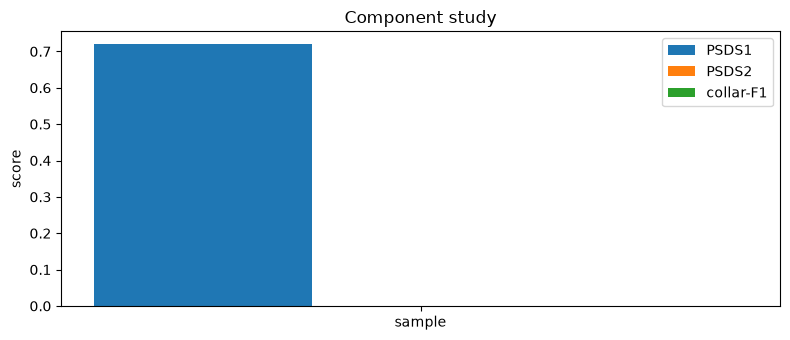

In [30]:
runs = {
    "BL": "crnn_baseline_urbansed",
    "+RED": "crnn_red_urbansed",
    "+OOL": "crnn_red_ool_urbansed",
    "+EPN": "crnn_red_epn_urbansed",
    "sample": "crnn_sample_wandb",
}
rows = []
for label, run in runs.items():
    path = ROOT / "results" / run / "test_metrics.json"
    if path.exists():
        m = json.loads(path.read_text())
        rows.append((label, m.get("psds1"), m.get("psds2"), m.get("collar_f1"),
                     m.get("frame_f1")))
    else:
        rows.append((label, None, None, None, None))

print(f"{'run':>7} {'PSDS1':>8} {'PSDS2':>8} {'collarF1':>10} {'frameF1':>8}")
for label, p1, p2, cf, ff in rows:
    fmt = lambda v: "   —   " if v is None else f"{v * 100:7.2f}"
    print(f"{label:>7} {fmt(p1)} {fmt(p2)} {fmt(cf)} {fmt(ff)}")

avail = [r for r in rows if r[1] is not None]
if avail:
    x = np.arange(len(avail)); w = 0.27
    plt.figure(figsize=(8, 3.5))
    plt.bar(x - w, [r[1] * 100 for r in avail], w, label="PSDS1")
    plt.bar(x, [r[2] * 100 for r in avail], w, label="PSDS2")
    plt.bar(x + w, [r[3] * 100 for r in avail], w, label="collar-F1")
    plt.xticks(x, [r[0] for r in avail]); plt.ylabel("score"); plt.legend()
    plt.title("Component study"); plt.tight_layout(); plt.show()
else:
    print("no test_metrics.json files yet")

### 6.3 Load predictions once

In [31]:
CKPT = ROOT / "checkpoints" / "crnn_sample_wandb" / "best.pt"
if not CKPT.exists():
    CKPT = ROOT / "checkpoints" / "crnn_red_epn_urbansed" / "best.pt"
print("checkpoint:", CKPT, CKPT.exists())

if not CKPT.exists():
    model = presence = don = doff = gt = None
    print("no checkpoint; the remaining cells will skip")
else:
    raw = torch.load(CKPT, map_location=device)
    saved = raw.get("extra", {}).get("model_cfg")
    if saved is None:
        saved = raw.get("extra", {}).get("cfg", {}).get("model", {})
    known = {f.name for f in __import__("dataclasses").fields(SEDConfig)}
    cfg = SEDConfig(**{k: v for k, v in saved.items() if k in known})
    model = build_model(cfg).to(device).eval()
    model.load_state_dict(raw["model"])

    ds = SEDDataset(DATA_ROOT, "validate")
    loader = DataLoader(ds, batch_size=32, shuffle=False, collate_fn=collate)
    presence, don, doff, gt = [], [], [], []
    with torch.no_grad():
        for batch in loader:
            out = model(batch["mel"].float().to(device))
            presence.append(presence_probability(out).cpu())
            if "don" in out:
                don.append(out["don"].cpu()); doff.append(out["doff"].cpu())
            for i in batch["index"].tolist():
                gt.append(ds.events[i] if ds.events else
                          frames_to_events(ds.targets["pres"][i].tolist(),
                                               cfg.frame_rate))
    presence = torch.cat(presence)
    don = torch.cat(don) if don else None
    doff = torch.cat(doff) if doff else None
    duration = len(gt) * cfg.num_frames / cfg.frame_rate
    print("clips:", len(gt), "duration (h):", duration / 3600)

checkpoint: /Users/minh.l/workspace/.researchs/event-proposal-networks-from-scratch/checkpoints/crnn_sample_wandb/best.pt True


clips: 300 duration (h): 0.8333333333333334


### 6.4 Median-filter grid

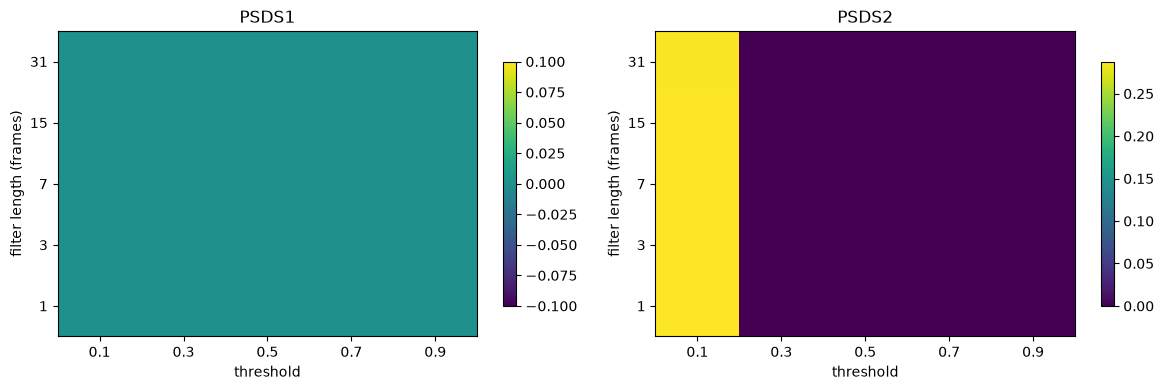

best median: filter_len=1 threshold=0.1 PSDS1=0.00


In [32]:
if model is None:
    print("skipped")
else:
    thresholds = [0.1, 0.3, 0.5, 0.7, 0.9]
    filter_lens = [1, 3, 7, 15, 31]
    grid = np.full((len(filter_lens), len(thresholds), 2), np.nan)
    for i, fl in enumerate(filter_lens):
        for j, th in enumerate(thresholds):
            preds = median_filter_events(presence, cfg.frame_rate,
                                             threshold=th, filter_len=fl)
            grid[i, j, 0] = psds1(preds, gt, dataset_duration=duration)["psds1"]
            grid[i, j, 1] = psds2(preds, gt, dataset_duration=duration)["psds2"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, name, idx in zip(axes, ["PSDS1", "PSDS2"], [0, 1]):
        im = ax.imshow(grid[:, :, idx], aspect="auto", origin="lower", cmap="viridis")
        ax.set_xticks(range(len(thresholds))); ax.set_xticklabels(thresholds)
        ax.set_yticks(range(len(filter_lens))); ax.set_yticklabels(filter_lens)
        ax.set_xlabel("threshold"); ax.set_ylabel("filter length (frames)")
        ax.set_title(name); fig.colorbar(im, ax=ax, shrink=0.8)
    plt.tight_layout(); plt.show()
    bi, bj = np.unravel_index(np.nanargmax(grid[:, :, 0]), grid[:, :, 0].shape)
    print(f"best median: filter_len={filter_lens[bi]} threshold={thresholds[bj]} "
          f"PSDS1={grid[bi, bj, 0] * 100:.2f}")

### 6.5 EPN inference sensitivity

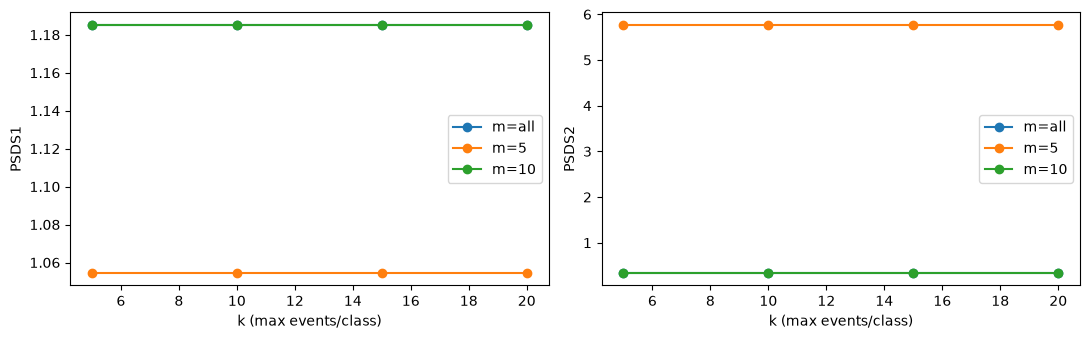

In [33]:
if model is None or don is None:
    print("skipped")
else:
    ks = [5, 10, 15, 20]
    ms = [None, 5, 10]
    table = np.full((len(ms), len(ks), 2), np.nan)
    for i, m in enumerate(ms):
        for j, k in enumerate(ks):
            preds = epn_inference(presence, don, doff, frame_rate=cfg.frame_rate,
                                      clip_duration=cfg.num_frames / cfg.frame_rate,
                                      k=k, m=m)
            table[i, j, 0] = psds1(preds, gt, dataset_duration=duration)["psds1"]
            table[i, j, 1] = psds2(preds, gt, dataset_duration=duration)["psds2"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for ax, name, idx in zip(axes, ["PSDS1", "PSDS2"], [0, 1]):
        for i, m in enumerate(ms):
            ax.plot(ks, table[i, :, idx] * 100, marker="o", label=f"m={m or 'all'}")
        ax.set_xlabel("k (max events/class)"); ax.set_ylabel(name); ax.legend()
    plt.tight_layout(); plt.show()

### 6.6 Boundary-error analysis

matched events 851
onset MAE  959.2 ms
offset MAE 756.7 ms
duration bias +480.9 ms


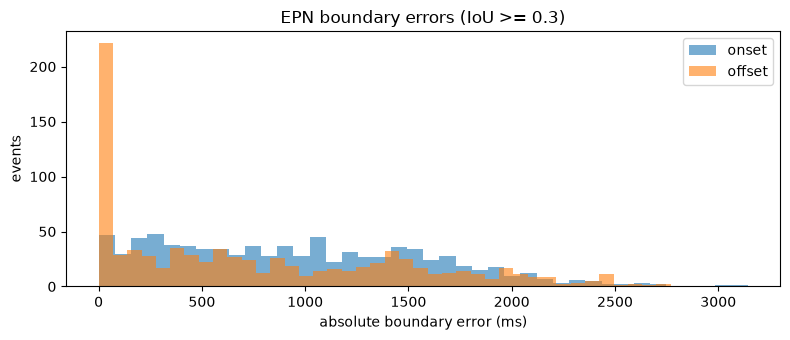

In [34]:
if model is None or don is None:
    print("skipped")
else:
    preds = epn_inference(presence, don, doff, frame_rate=cfg.frame_rate,
                              clip_duration=cfg.num_frames / cfg.frame_rate,
                              k=15, m=None)
    onset_err, offset_err, dur_err = [], [], []
    for p_clip, g_clip in zip(preds, gt):
        for g in g_clip:
            cand = [(iou(p, g), p) for p in p_clip if p.class_id == g.class_id]
            if not cand:
                continue
            best_iou, best = max(cand, key=lambda x: x[0])
            if best_iou < 0.3:
                continue
            onset_err.append(abs(best.onset - g.onset))
            offset_err.append(abs(best.offset - g.offset))
            dur_err.append((best.offset - best.onset) - g.duration)
    if onset_err:
        print(f"matched events {len(onset_err)}")
        print(f"onset MAE  {np.mean(onset_err) * 1000:.1f} ms")
        print(f"offset MAE {np.mean(offset_err) * 1000:.1f} ms")
        print(f"duration bias {np.mean(dur_err) * 1000:+.1f} ms")
        plt.figure(figsize=(8, 3.5))
        plt.hist(np.asarray(onset_err) * 1000, bins=40, alpha=0.6, label="onset")
        plt.hist(np.asarray(offset_err) * 1000, bins=40, alpha=0.6, label="offset")
        plt.xlabel("absolute boundary error (ms)"); plt.ylabel("events")
        plt.legend(); plt.title("EPN boundary errors (IoU >= 0.3)")
        plt.tight_layout(); plt.show()
    else:
        print("no matched events")

## Interpretation prompts

- Does `BL < +RED < +OOL < +EPN` hold?
- Does EPN beat the best median-filter grid without per-class tuning?
- Are onset/offset errors symmetric, or is duration biased?
- Does PSDS2 stay more stable than PSDS1 across `k`/`m`?